In [1]:
import torch

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import json

In [699]:
def draw_plots(path):
    with open(path, "r") as f:
        dic = json.load(f)
    history = dic["history"]
    batch_hist = [row for row in history if "batch_idx" in row]
    epoch_hist = [row for row in history if "batch_idx" not in row]
    bdf = pd.DataFrame(batch_hist)
    edf = pd.DataFrame(epoch_hist)
    # fractional epoch: 2.5 == halfway through epoch 2
    bdf["progress"] = bdf["epoch"] + bdf["batch_percentage"]
    # epoch-level rows are logged at the *end* of the epoch
    edf["progress"] = edf["epoch"] + 1

    train_c, val_c, time_c = "#2a78d6", "#eb6834", "#1baf7a"
    fig, (ax_loss, ax_time, ax_gap,ax_non_smooth) = plt.subplots(
        4, 1, figsize=(16, 16), sharex=True, constrained_layout=True
    )
    fig.suptitle(f"Training run: {path}", fontsize=13)

    # 1) batch loss with epoch-level averages overlaid on the same timeline
    ax_loss.plot(bdf["progress"], bdf["batch_loss"], color=train_c, lw=1,
                 alpha=0.6, label="train loss (per batch)")
    ax_loss.plot(edf["progress"], edf["avg_loss"], color=train_c, lw=2,
                 marker="o", ms=5, label="train loss (epoch avg)")
    ax_loss.plot(edf["progress"], edf["avg_vloss"], color=val_c, lw=2,
                 marker="o", ms=5, label="val loss (epoch avg)")
    ax_loss.set_yscale("log")
    ax_loss.yaxis.set_major_formatter(ScalarFormatter())
    ax_loss.yaxis.set_minor_formatter(ScalarFormatter())
    ax_loss.set_ylabel("cross-entropy loss (log scale)")
    ax_loss.set_title("Loss")
    ax_loss.legend(loc="upper right")

    # 2) per-batch step time
    ax_time.plot(bdf["progress"], bdf["tokens/sec"], color=time_c, lw=1)
    ax_time.set_ylabel("tokens/sec")
    ax_time.set_title("tokens/sec")

    # 3) train/val gap per epoch
    ax_gap.plot(edf["progress"], edf["avg_vloss"] - edf["avg_loss"],
                color=val_c, lw=2, marker="o", ms=5)
    ax_gap.axhline(0, color="0.6", lw=1, ls="--")
    ax_gap.set_ylabel("val loss − train loss")
    ax_gap.set_title("Generalization gap (positive = val worse than train)")
    ax_gap.set_xlabel("epoch")

    # 4) batch non smoothed CE with epoch-level averages overlaid on the same timeline
    if "non_smoothed_loss_fn_val" in edf:
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn"], color=train_c, lw=2,
                    marker="o", ms=5, label="train non smoothed CE (epoch avg)")
        ax_non_smooth.plot(edf["progress"], edf["non_smoothed_loss_fn_val"], color=val_c, lw=2,
                    marker="o", ms=5, label="val non smoothed CE (epoch avg)")
        ax_non_smooth.set_yscale("log")
        ax_non_smooth.yaxis.set_major_formatter(ScalarFormatter())
        ax_non_smooth.yaxis.set_minor_formatter(ScalarFormatter())
        ax_non_smooth.set_ylabel("cross-entropy loss (log scale)")
        ax_non_smooth.set_title("Non Smoothed Loss")
        ax_non_smooth.legend(loc="upper right")

    for ax in (ax_loss, ax_time, ax_gap,ax_non_smooth):
        ax.grid(True, color="0.9", lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    ax_gap.set_xlim(0, edf["progress"].max())
    ax_gap.set_xticks(range(0, int(edf["progress"].max()) + 1))

    plt.show()
    return bdf, edf, batch_hist

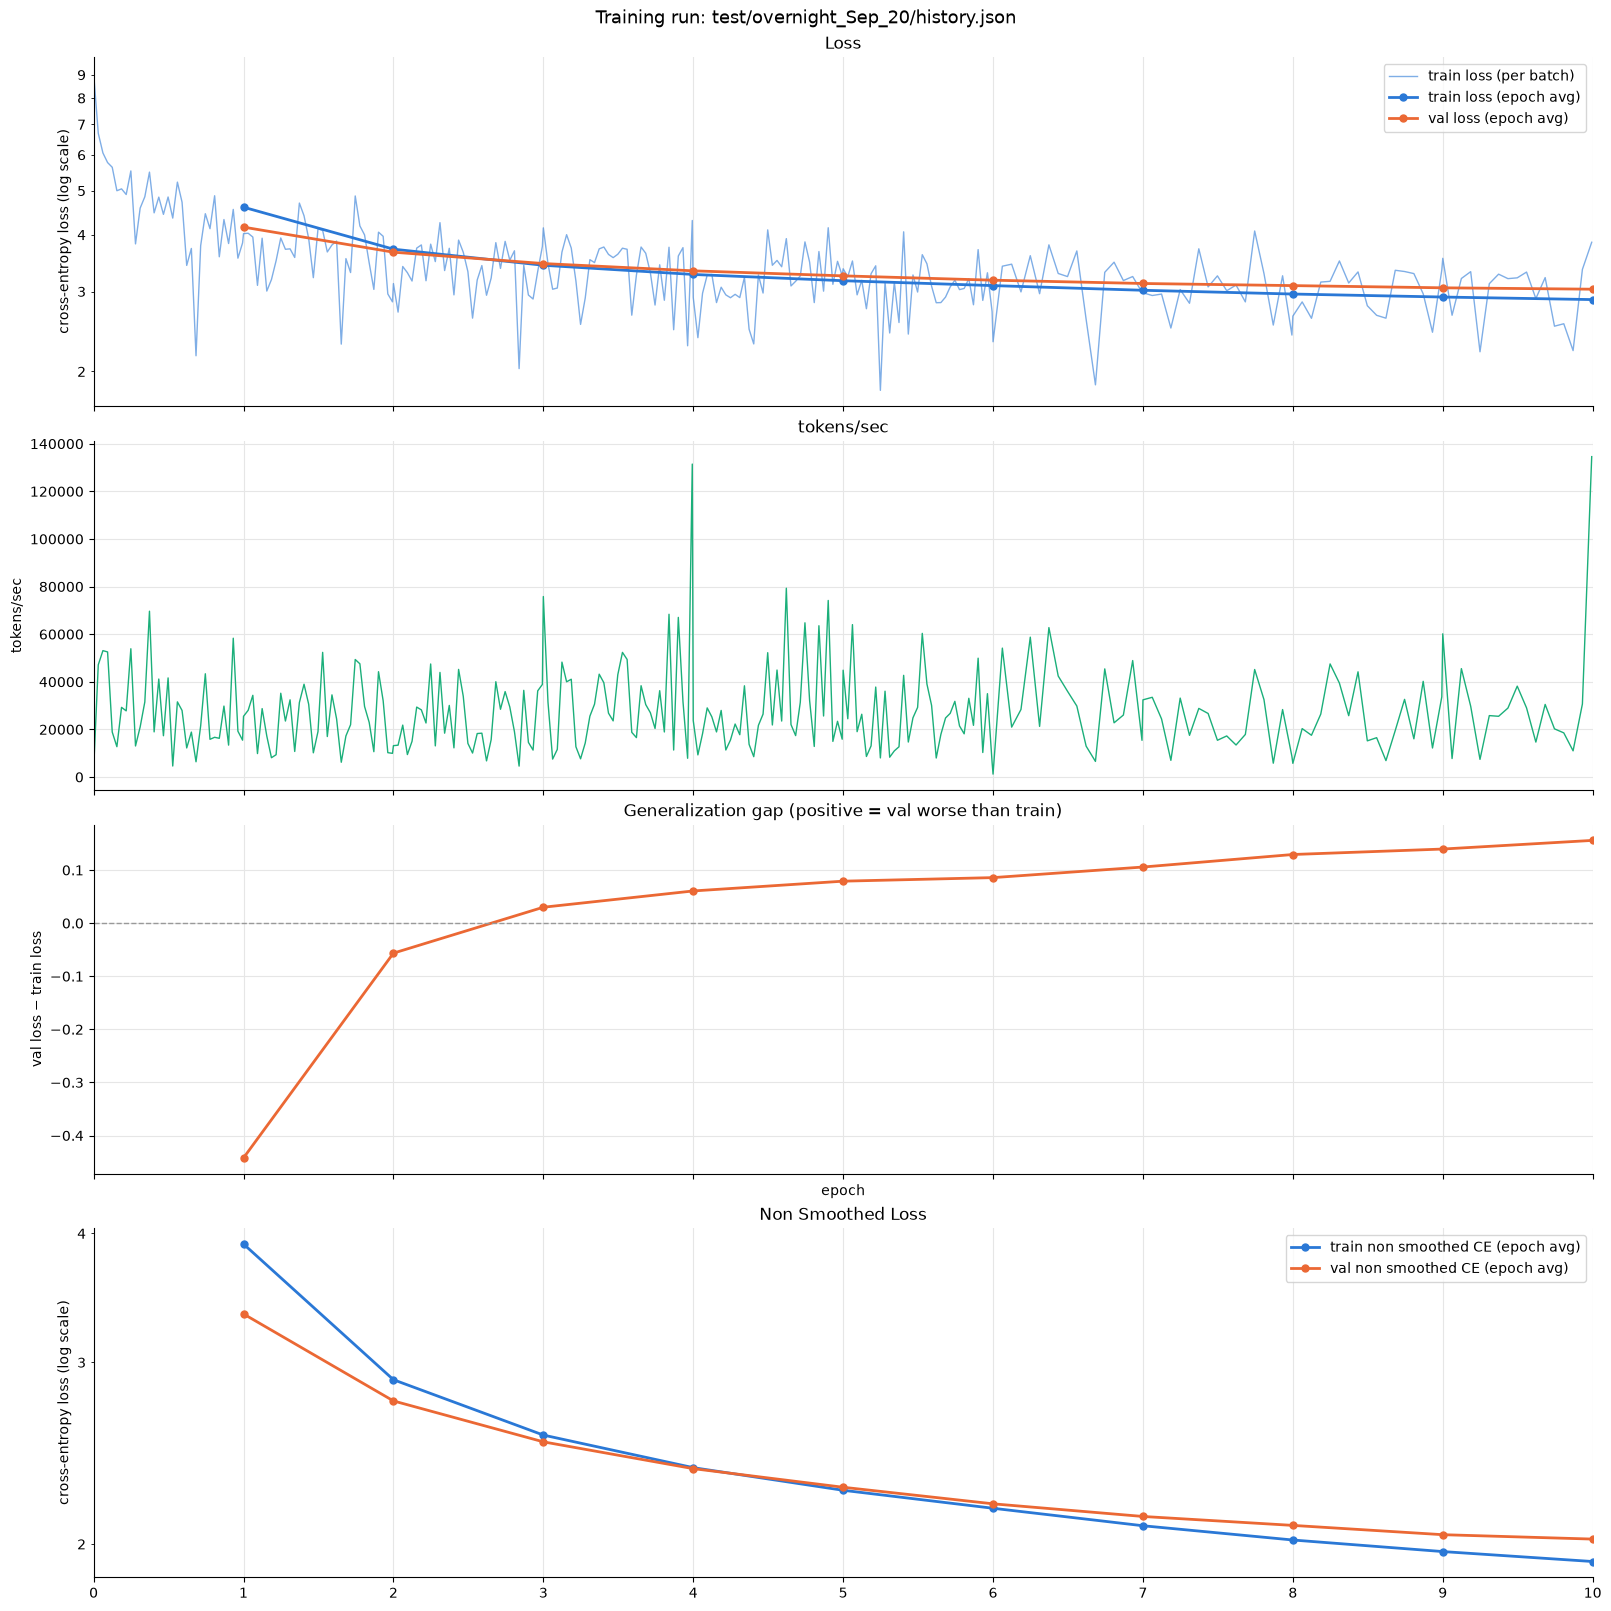

In [700]:
bdf_1,edf_1,batch_hist_1 = draw_plots("test/overnight_Sep_20/history.json")

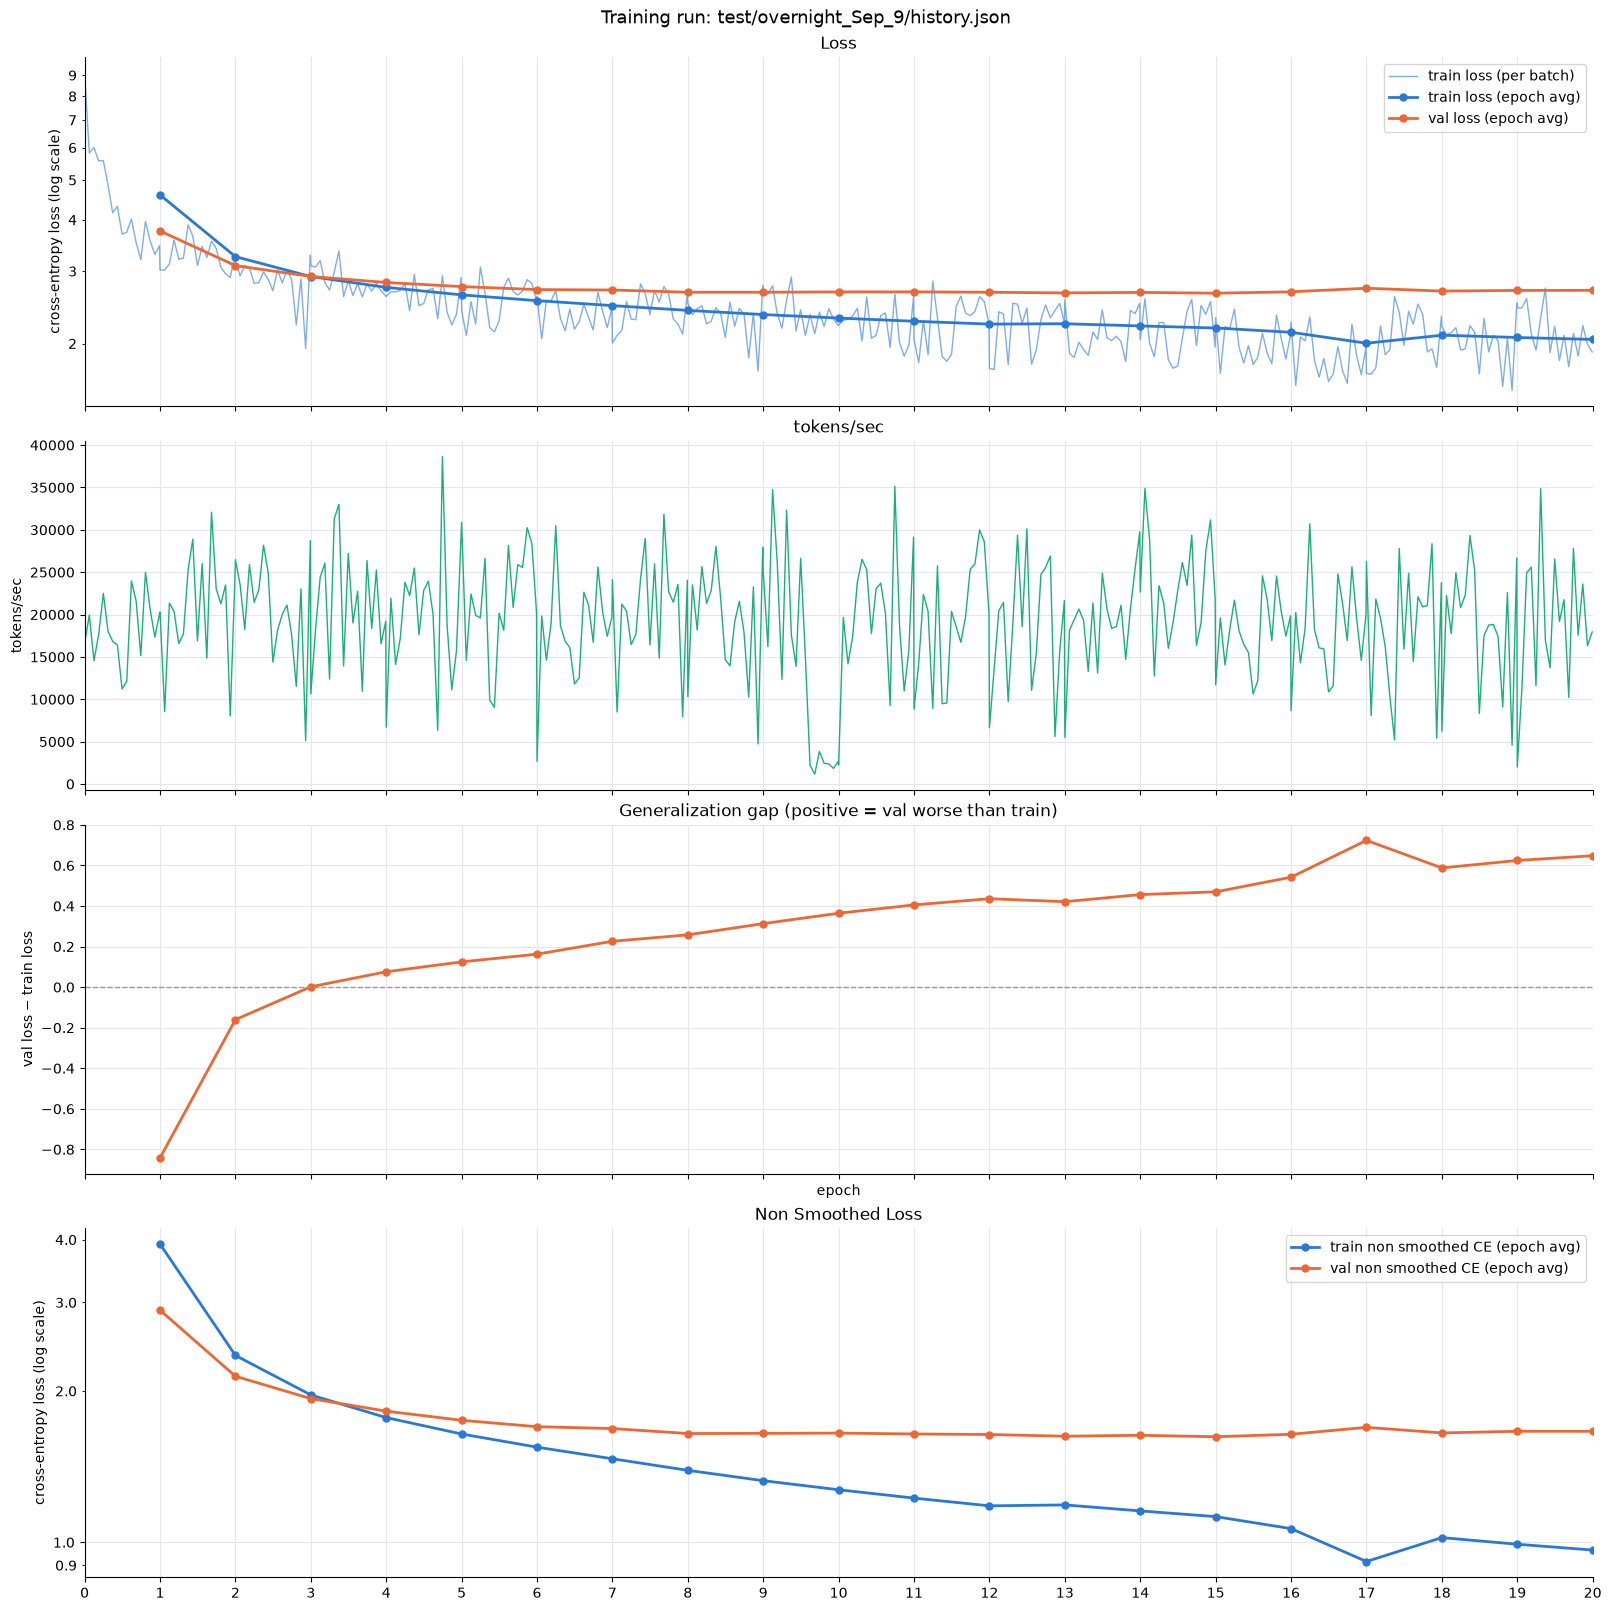

In [132]:
bdf_9,edf_9,batch_hist_9 = draw_plots("test/overnight_Sep_9/history.json")

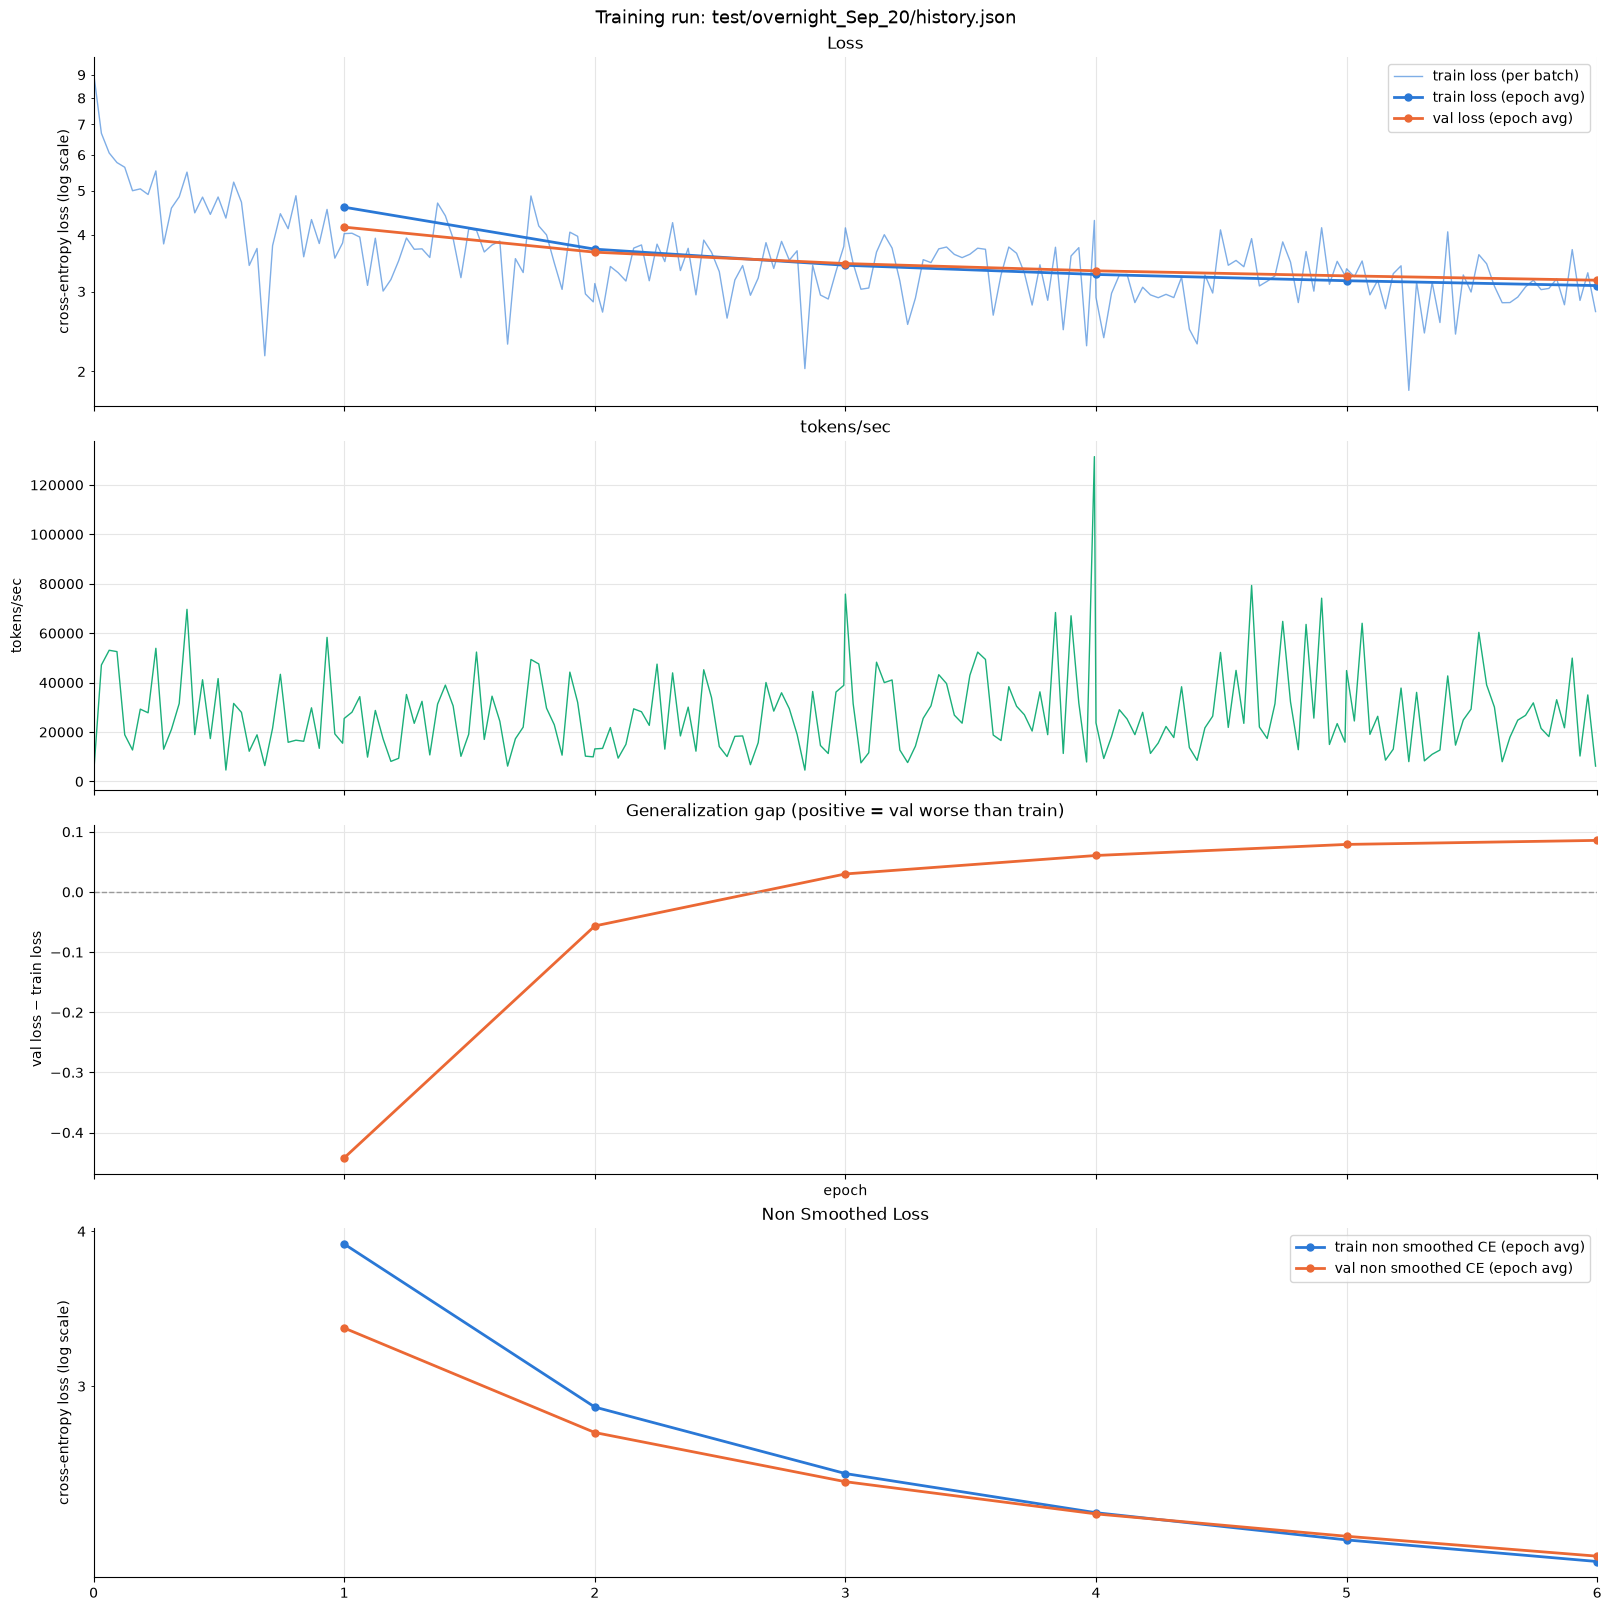

In [431]:
bdf_20,edf_20,batch_hist_20 = draw_plots("test/overnight_Sep_20/history.json")

In [34]:
edf_9.head(15)

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,non_smoothed_loss_fn,non_smoothed_loss_fn_val,progress
0,4.600607,3.758963,0,0.224054,728.235123,3.920981,2.896056,1
1,3.254810,3.094645,1,0.209575,678.188980,2.353563,2.139516,2
2,2.910920,2.912854,2,0.210596,681.275587,1.964267,1.931431,3
3,2.739887,2.815850,3,0.209165,677.109155,1.770508,1.823554,4
4,2.627254,2.751852,4,0.216819,701.441065,1.642390,1.748690,5
5,2.543219,2.705959,5,0.212776,688.588208,1.546178,1.698275,6
6,2.473586,2.699756,6,0.222507,723.793479,1.466149,1.683775,7
7,2.408184,2.666172,7,0.212738,688.601492,1.390481,1.645912,8
8,2.352896,2.666194,8,0.215717,698.024706,1.326126,1.647046,9
9,2.306764,2.671209,9,0.941349,3042.422582,1.272158,1.649126,10


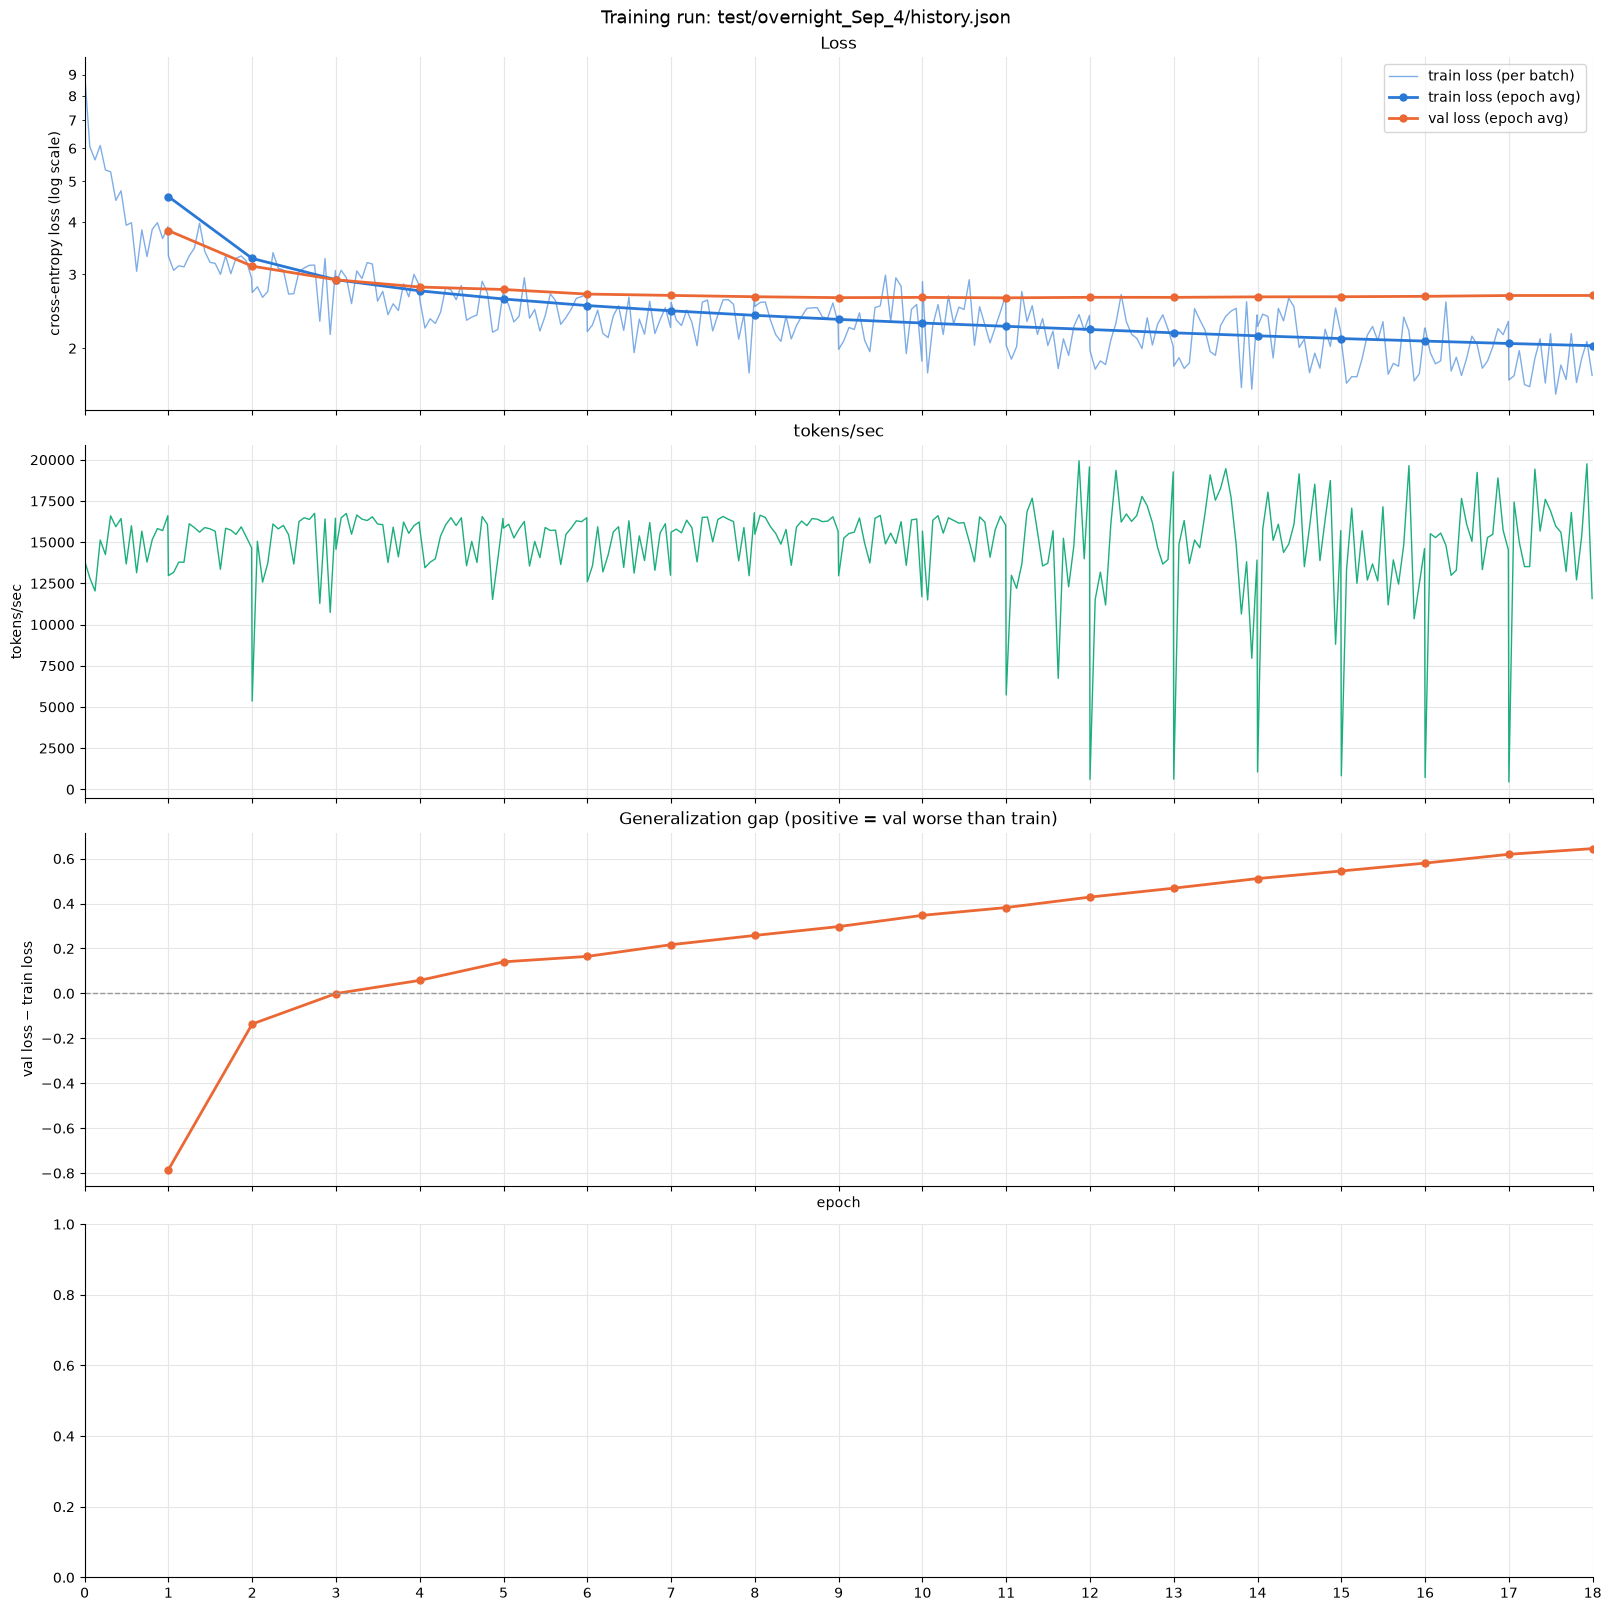

In [35]:
bdf_4,edf_4,batch_hist_4 = draw_plots("test/overnight_Sep_4/history.json")

In [39]:
edf_9.tail()

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,non_smoothed_loss_fn,non_smoothed_loss_fn_val,progress
10,2.266102,2.671711,10,5.687125,18322.971654,1.224391,1.642623,11
11,2.229962,2.666012,11,0.227476,736.717623,1.181746,1.638492,12
12,2.234758,2.656166,12,0.240112,777.003948,1.186867,1.625808,13
13,2.207198,2.663669,13,0.230644,746.697238,1.154674,1.632523,14
14,2.181914,2.651884,14,0.227799,737.663092,1.124939,1.621985,15


In [38]:
edf_4.tail()

,avg_loss,avg_vloss,epoch,avg_time,epoch_time,progress
13,2.141576,2.652772,13,0.311864,1009.196979,14
14,2.109560,2.654568,14,0.331522,1073.104000,15
15,2.080353,2.660345,15,0.314727,1018.333488,16
16,2.053056,2.672292,16,0.316467,1024.179829,17
17,2.028260,2.672870,17,0.322529,1043.856056,18


In [26]:
import sentencepiece
import torch
from torch.distributions import Categorical
from torchmetrics.text import BLEUScore

In [ ]:
import importlib
import train
importlib.reload(train)
from train import DEVICE, config, load_best_model

In [433]:
model, _, history = load_best_model()



num_parameters: 32,985,088 - num_non_embedding_params: 29,401,088
2026-09-20 10:41:17.201892: loss_fn loaded
2026-09-20 10:41:17.202562: loading best pre saved
best model path found.
2026-09-20 10:41:19.779235: Starting from pre saved with: start_epoch: 19, best_val_loss: 2.6519, last_epoch_vloss: 2.69, non_improve_cnt: 2.00


In [434]:
sp_bpe = sentencepiece.SentencePieceProcessor()
sp_bpe.load("bpe.model")
metric = BLEUScore()

In [442]:
english_orig_translation = "Write your name in my book."
german_text = "Schreib deinen Namen in mein Buch."
german_list_enc = sp_bpe.encode_as_ids(german_text, add_bos=True, add_eos=True)
german_encoding = torch.tensor([german_list_enc]).to(DEVICE)

english_encoding = [sp_bpe.bos_id()]

i = 0
model.eval()
with torch.no_grad():
    while i < 20:
        logits = model.forward(german_encoding,torch.tensor([english_encoding]).to(DEVICE)) # B,Sy,VS
        dist = Categorical(logits=logits[0,-1,:])

        new_enc = dist.sample().item()
        english_encoding.append(new_enc)
        print(f"debug: new encoding: '{sp_bpe.decode_ids(english_encoding)}'")
        if new_enc == sp_bpe.eos_id():
            print("debug: reached EOS")
            break 
        i+=1
score = metric([sp_bpe.decode_ids(english_encoding)], [[english_orig_translation]])
print(f"BLEU Score: {score}")

debug: new encoding: 'Ste'
debug: new encoding: 'Stept'
debug: new encoding: 'Stept your'
debug: new encoding: 'Stept your name'
debug: new encoding: 'Stept your name in'
debug: new encoding: 'Stept your name in my'
debug: new encoding: 'Stept your name in my book'
debug: new encoding: 'Stept your name in my book.'
debug: new encoding: 'Stept your name in my book.'
debug: reached EOS
BLEU Score: 0.7598356604576111


In [83]:
print(english_orig_translation)
print(sp_bpe.decode_ids(english_encoding))

Let's talk about the environment.
Let's talk about the environment.


In [49]:
metric(["Hello this is a cat"], [["Hi this is a dog"]])

tensor(0.)

In [ ]:
# getting val data setup
def encode(item):
    ids = sp_bpe.encode_as_ids(item, add_bos=True)
    return np.array(ids[:128-1]+[sp_bpe.eos_id()], dtype=np.int64)


val_df = pd.read_csv("val_df.csv")

debug: len(val_dt): 888


In [ ]:
totalscore = 0
translation = []
reached_eos = 0
for i,row in val_df.iterrows():
    print(f"debug: at idx: {i}", end=": ")
    
    english_encoding = [sp_bpe.bos_id()]
    x = torch.tensor(encode(row["detext"]), device=DEVICE).reshape((1,-1))
    while i < 120:
        y = torch.tensor([english_encoding],dtype=torch.long, device=DEVICE)
        logits = model(x,y) # B,Sy,VS
        cur_id = torch.argmax(logits,dim=2)[0,-1]
        english_encoding.append(cur_id)
        if cur_id == sp_bpe.eos_id():
            reached_eos+=1
            break
    y_pred = [sp_bpe.decode_ids(english_encoding)]

    y = [[row["entext"]]]
    score = metric(y_pred,y)
    translation.append((y_pred[0],y[0][0],score))
    totalscore+=score
    print(score)

reached_eos/=len(val_df)
totalscore/=len(val_df)

debug: at idx: 0: tensor(0.2638)
debug: at idx: 1: tensor(0.5683)
debug: at idx: 2: tensor(0.2595)
debug: at idx: 3: tensor(0.)
debug: at idx: 4: tensor(0.4581)
debug: at idx: 5: tensor(0.)
debug: at idx: 6: tensor(0.1912)
debug: at idx: 7: tensor(0.2741)
debug: at idx: 8: tensor(0.)
debug: at idx: 9: tensor(0.2361)
debug: at idx: 10: tensor(0.2447)
debug: at idx: 11: tensor(0.)
debug: at idx: 12: tensor(0.2031)
debug: at idx: 13: tensor(0.)
debug: at idx: 14: tensor(0.)
debug: at idx: 15: tensor(0.)
debug: at idx: 16: tensor(0.)
debug: at idx: 17: tensor(0.)
debug: at idx: 18: tensor(0.2535)
debug: at idx: 19: tensor(0.)
debug: at idx: 20: tensor(0.5129)
debug: at idx: 21: tensor(0.)
debug: at idx: 22: tensor(0.)
debug: at idx: 23: tensor(0.)
debug: at idx: 24: tensor(0.2989)
debug: at idx: 25: tensor(0.7703)
debug: at idx: 26: tensor(0.4948)
debug: at idx: 27: tensor(0.)
debug: at idx: 28: tensor(0.)
debug: at idx: 29: tensor(0.)
debug: at idx: 30: tensor(0.)
debug: at idx: 31: tenso

KeyboardInterrupt: 

In [117]:
translation[0]

NameError: name 'translation' is not defined

In [443]:
from train import load_data, lr_update_fn
import torch

In [39]:
config["mega_batch_size"]

50

In [129]:
train_loader, val_loader = load_data()

2026-09-19 16:23:35.639151: # train sentences 206,112
2026-09-19 16:23:35.639297: # train docs 1,705
2026-09-19 16:23:35.639304: # val sentences 888
   Unnamed: 0 index  docid  segid  \
0           0   1,1      1      1   
1           1   1,2      1      2   
2           2   1,3      1      3   
3           3   1,4      1      4   
4           4   1,5      1      5   

                                              entext  \
0                          Thank you so much, Chris.   
1  And it's truly a great honor to have the oppor...   
2  I have been blown away by this conference, and...   
3  And I say that sincerely, partly because  I ne...   
4                     Put yourselves in my position.   

                                              detext  
0                                Vielen Dank, Chris.  
1  Es ist mir wirklich eine Ehre, zweimal auf die...  
2  Ich bin wirklich begeistert von dieser Konfere...  
3  Das meine ich ernst, teilweise deshalb -- weil...  
4              V

In [120]:
total_x = 0
total_y = 0
x_len=0
y_len=0

pad_tokens = 0
for X,Y in train_loader: # B,Sy
    cur_x = torch.sum(X != config["pad_token"])
    cur_y = torch.sum(Y != config["pad_token"])
    pad_tokens += X.shape[0] * (X.shape[1] + Y.shape[1]) - cur_x - cur_y
    total_x+=cur_x
    total_y+=cur_y

    x_len+=X.shape[1]
    y_len+=Y.shape[1]

Python(30243) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(30244) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Python(30294) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


In [121]:
print(f"total_x: {total_x.item():,}")
print(f"total_y: {total_y.item():,}")
print(f"total_pad_tokens: {pad_tokens.item():,}")

print("per step: ")
print(f"total_x: {total_x / len(train_loader):,.2f}")
print(f"total_y: {total_y / len(train_loader):,.2f}")
print(f"pad_tokens: {pad_tokens / len(train_loader) / 2:,.2f}")
print(f"X_len: {x_len / len(train_loader):.2f}")
print(f"Y_len: {y_len / len(train_loader):.2f}")

total_x: 5,838,142
total_y: 5,697,404
total_pad_tokens: 2,653,126
per step: 
total_x: 1,812.52
total_y: 1,768.83
pad_tokens: 411.85
X_len: 29.00
Y_len: 39.86


In [123]:
batches_per_epoch_me = 3221 # from logs/output_logs_overnight_Sep_5_2.txt
num_epochs_me = 15
sent_len_me = (x_len + y_len)/(2*len(train_loader))
sent_len_them = sent_len_me #??
print(f"tokens seen total: {100_000 * 25_000:,} - {(total_x) * num_epochs_me:,}")
print(f"tokens/batch:      {25_000:,} - {(total_x + total_y)/len(train_loader):,.0f}")
print(f"tokens/epoch:      {4_500_000 * sent_len_them:,.0f} - {total_x + total_y:,}") # assuming they have the same sentence length as us
print(f"batches/epoch:     {(4_500_000 * sent_len_them / 25_000):,.0f} - {batches_per_epoch_me:,}") # batches_t * tokens/epoch / tokens_t
print(f"epochs:            {100_000 / ((4_500_000 * sent_len_them / 25_000)):.1f} - {num_epochs_me}")
print(f"batches:           {100_000:,} - {batches_per_epoch_me * num_epochs_me:,.2f}")

tokens seen total: 2,500,000,000 - 87,572,130
tokens/batch:      25,000 - 3,581
tokens/epoch:      154,948,230 - 11,535,546
batches/epoch:     6,198 - 3,221
epochs:            16.1 - 15
batches:           100,000 - 48,315.00


took back: 

- higher tokens/batch than paper -> less gradient noise. Hence better. 
- batches/epoch is half -> Noam LR is still warming up at the start
- total batches is third -> Noam LR is not fully calmed down yet at the end -> lower warmup_steps. 
- 

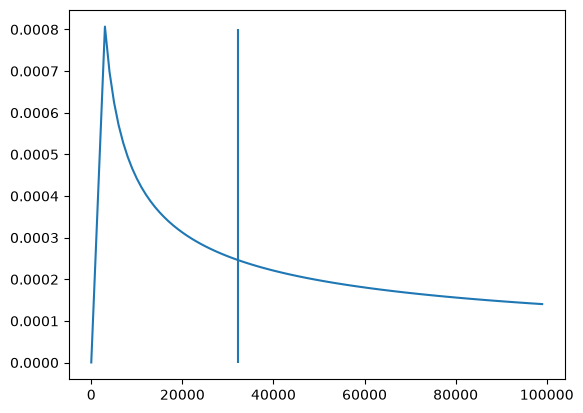

In [80]:
plt.plot([i for i in range(0,100_000,1_000)],[lr_update_fn(i) for i in range(0,100_000,1_000)])
plt.vlines(32_210,ymin=0,ymax=0.0008)

In [48]:
import torch
d = torch.nn.Dropout(0.1).train()
x = torch.ones(1, 8, 512)          # B, S, d_model
out = d(x)
print((out == 0).float().mean())    # fraction of individual numbers zeroed
print((out == 0).all(dim=-1).sum()) # how many whole tokens zeroed


tensor(0.1008)
tensor(0)


In [ ]:
x = torch.rand((3,2))
x[1,0] = 1

In [161]:
x

tensor([[0.7539, 0.1952],
        [1.0000, 0.3068],
        [0.1165, 0.9103]])

In [156]:
np.argwhere(x == 0.0050)

tensor([], size=(2, 0), dtype=torch.int64)

In [164]:
x == 1

tensor([[False, False],
        [ True, False],
        [False, False]])

In [459]:
import importlib
import train
importlib.reload(train)
from train import calculate_bleu, load_best_model

In [460]:
model, _, history = load_best_model()



num_parameters: 32,985,088 - num_non_embedding_params: 29,401,088
2026-09-20 10:53:13.733250: loss_fn loaded
2026-09-20 10:53:13.733455: loading best pre saved
best model path found.
2026-09-20 10:53:14.042240: Starting from pre saved with: start_epoch: 19, best_val_loss: 2.6519, last_epoch_vloss: 2.69, non_improve_cnt: 2.00


In [461]:
gen = calculate_bleu(val_loader,model,sp_bpe)

at: 0/14
avg_bleu: 27.39, avg_cnt: 22.05
at: 1/14
avg_bleu: 28.95, avg_cnt: 22.20
at: 2/14
avg_bleu: 27.55, avg_cnt: 22.89
at: 3/14
avg_bleu: 25.67, avg_cnt: 23.80
at: 4/14
avg_bleu: 25.17, avg_cnt: 24.67
at: 5/14
avg_bleu: 24.74, avg_cnt: 24.97
at: 6/14
avg_bleu: 25.50, avg_cnt: 25.43
at: 7/14
avg_bleu: 25.99, avg_cnt: 25.48
at: 8/14
avg_bleu: 25.87, avg_cnt: 26.23
at: 9/14
avg_bleu: 25.86, avg_cnt: 27.72
at: 10/14
avg_bleu: 25.36, avg_cnt: 28.86
at: 11/14
avg_bleu: 25.54, avg_cnt: 28.33
at: 12/14
avg_bleu: 25.40, avg_cnt: 28.12
at: 13/14
avg_bleu: 25.70, avg_cnt: 27.82


In [462]:
gen

(tensor(0.2570),
 27.8231981981982,
 888,
 [{'orig': 'Last year I showed these two slides so that demonstrate that the arctic ice cap, which for most of the last three million years has been the size of the lower 48 states, has shrunk by 40 percent.',
   'trans': 'Last year, I showed these two slides to illustrate that the Arctic ice caps that had the size of the under 48 countries to shrink for nearly three million years.'},
  {'orig': "But this understates the seriousness of this particular problem because it doesn't show the thickness of the ice.",
   'trans': "But that doesn't really express strongly enough to the seriousness of this particular problem, because it doesn't show the ice ice ice."},
  {'orig': 'The arctic ice cap is, in a sense, the beating heart of the global climate system.',
   'trans': 'In a sense, the Arctic ice cap is the beating heart of our global climate system.'},
  {'orig': 'It expands in winter and contracts in summer.',
   'trans': 'It grows in the winter

In [ ]:
df_20 = pd.DataFrame(gen_20[3])

In [ ]:
df_20 = pd.DataFrame(gen_20[3])

In [456]:
df_20.head()

,orig,trans
0,Last year I showed these two slides so that de...,"Last year, I showed these two slides to illust..."
1,But this understates the seriousness of this p...,But that doesn't really express strongly enoug...
2,"The arctic ice cap is, in a sense, the beating...","In a sense, the Arctic ice cap is the beating ..."
3,It expands in winter and contracts in summer.,"It grows in the winter, shrinks in the summer."
4,The next slide I show you will be a rapid fast...,The next slide I'm showing you is a time-lapse...


In [463]:
gen_20[:3]

(tensor(0.2570), 27.8231981981982, 888)

In [469]:
type(torch.float16).__module__.startswith("torch")

True

In [687]:
NUM_TOKENS=0
val_df = pd.read_csv("val_df.csv")
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids[:128-1]+[sp_bpe.eos_id()], dtype=np.int64)
val_df['x_enc'] = [len(encode(item)) for item in val_df["entext"]]
val_df["detext"] = val_df["detext"].str.replace("<br","")
sorted_df = val_df.sort_values("x_enc").reset_index().drop(columns=["Unnamed: 0", "x_enc", "level_0"])
# sorted_df.to_csv("val_sorted_df.csv",index=False)

In [698]:
sorted_df.to_csv("val_sorted_df.csv")

In [689]:
NUM_TOKENS=0
train_df = pd.read_csv("train_df.csv")
def encode(item):
        global NUM_TOKENS
        ids = sp_bpe.encode_as_ids(item, add_bos=True)
        NUM_TOKENS+=len(ids)
        return np.array(ids+[sp_bpe.eos_id()], dtype=np.int64)
train_df["detext"] = train_df["detext"].str.replace("<br","")
# Remove anything between [...] and ♪ and long sentences. 
train_df['x_enc'] = [len(encode(item)) for item in train_df["entext"]]
train_df['y_enc'] = [len(encode(item)) for item in train_df["detext"]]
train_df["ratio"] = train_df["x_enc"] / train_df["y_enc"]

In [690]:
en_value_counts = train_df.groupby("entext")["entext"].transform("count")
de_value_counts = train_df.groupby("detext")["detext"].transform("count")
en_counter = train_df.groupby("entext").cumcount()
de_counter = train_df.groupby("detext").cumcount()
mask = (
    ((en_value_counts < 10) | (en_counter < 5)) & 
    ((de_value_counts < 10) | (de_counter < 5)) & 
    (train_df["x_enc"] >= 4) & 
    (train_df["y_enc"] > 4) & 
    (train_df["ratio"] >= 0.4) & 
    (train_df["ratio"] <= 2.5)
)
filtered_df = train_df[mask]

In [695]:
filtered_df.head()

,Unnamed: 0,index,docid,segid,entext,detext,x_enc,y_enc,ratio
0,0,"1,1",1,1,"Thank you so much, Chris.","Vielen Dank, Chris.",9,7,1.285714
1,1,"1,2",1,2,And it's truly a great honor to have the oppor...,"Es ist mir wirklich eine Ehre, zweimal auf die...",31,26,1.192308
2,2,"1,3",1,3,"I have been blown away by this conference, and...",Ich bin wirklich begeistert von dieser Konfere...,37,36,1.027778
3,3,"1,4",1,4,"And I say that sincerely, partly because I ne...","Das meine ich ernst, teilweise deshalb -- weil...",18,18,1.000000
4,4,"1,5",1,5,Put yourselves in my position.,Versetzen Sie sich mal in meine Lage!,10,11,0.909091


In [697]:
filtered_df.drop(columns=["Unnamed: 0","x_enc","y_enc","ratio"]).to_csv("train_filtered_df.csv")

In [693]:
mask.value_counts()

True     204423
False      1689
Name: count, dtype: int64